# Two maps, two scales

Fourth piece in this thread, built as supporting material for the redlining piece's closing section rather than published standalone. `dc_ej_predictors.ipynb` found physical siting infrastructure explains 62% of WA's real EJ index, mostly through one urban/rural axis (`dc_ej_urban_axis_pca.ipynb`, PC1, 24.6% of indicator variance). `dc_ej_redlining.ipynb` found a 90-year-old redlining map explains 18% of the same real EJ index -- but only *within* the three cities HOLC covered. Put side by side, an obvious question: do these compete, or combine?

They do neither. They answer the question at two different zoom levels. This notebook makes that precise and visual instead of leaving it as a chat conversation.

**Leakage correction (2026-08-28):** built on the same corrected `urban_axis` as `dc_ej_urban_axis_pca.ipynb` -- PCA on the 17 honest indicators only, excluding the 4 hazard columns that are literally the raw ingredients of `env_burden` (half of `ej_index`'s own formula). An earlier version of this notebook (and the companion PCA piece) included them, which inflated the statewide number. See that notebook's intro for the full story.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

zctas = gpd.read_file("../../merascope/data/WA/zcta/grid_scores.geojson")
acs = pd.read_csv("data/acs_demog_moe_tract_wa.csv", dtype={"GEOID": str})
tracts = gpd.read_file("../../merascope/data/WA/raw/tracts.geojson")[["GEOID", "geometry"]].merge(acs, on="GEOID")

zctas_m = zctas.to_crs(3857)
tracts_m = tracts.set_geometry("geometry").to_crs(3857)
tracts_m["tract_area"] = tracts_m.geometry.area
overlay_t = gpd.overlay(zctas_m[["zcta", "geometry"]], tracts_m, how="intersection", keep_geom_type=False)
overlay_t["piece_area"] = overlay_t.geometry.area
overlay_t = overlay_t.merge(tracts_m[["GEOID", "tract_area"]], on="GEOID", suffixes=("", "_full"))
overlay_t["pop_weight"] = overlay_t["tract_pop"] * (overlay_t["piece_area"] / overlay_t["tract_area"])


def weighted_demog(g):
    w = g["pop_weight"]
    return pd.Series({"demog_index": np.nan}) if w.sum() <= 0 else pd.Series({"demog_index": np.average(g["demog_index"], weights=w)})


zcta_di = overlay_t.groupby("zcta").apply(weighted_demog, include_groups=False).reset_index()
zctas = zctas.merge(zcta_di, on="zcta", how="left")
ENV_HAZARD_COLS = ["contamination_score", "superfund_score", "rcra_score", "air_quality_score"]
zctas["env_burden"] = 1 - zctas[ENV_HAZARD_COLS].mean(axis=1)
zctas["ej_index"] = zctas["demog_index"] * zctas["env_burden"]
zctas = zctas.dropna(subset=["ej_index"]).copy()

# Leakage guard, by construction: env_burden (half of ej_index) is built from ENV_HAZARD_COLS,
# so they're excluded from the PCA input entirely -- not just flagged afterward.
PCA_COLS = [c for c in zctas.columns
            if c.endswith("_score") and not c.endswith("_score_nat")
            and c not in ("ej_score", "grid_capacity_score")
            and c not in ENV_HAZARD_COLS]
assert not (set(PCA_COLS) & set(ENV_HAZARD_COLS)), "a hazard column leaked back into the PCA input"

Xs = StandardScaler().fit_transform(zctas[PCA_COLS].to_numpy())
pca = PCA(n_components=len(PCA_COLS), random_state=0)
scores = pca.fit_transform(Xs)
pc1 = scores[:, 0]
if np.corrcoef(pc1, zctas["fiber_score"])[0, 1] < 0:
    pc1 = -pc1
zctas["urban_axis"] = pc1
print(f"{len(zctas)} WA ZCTAs, urban axis built (same leakage-checked PCA as dc_ej_urban_axis_pca.ipynb)")

ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/anaconda3/envs/merascope/share/proj failed


591 WA ZCTAs, urban axis built (same leakage-checked PCA as dc_ej_urban_axis_pca.ipynb)


In [2]:
holc = gpd.read_file("data/mappinginequality_wa.geojson")
holc_m = holc.to_crs(3857)
CITIES = ["Seattle", "Tacoma", "Spokane"]
GRADE_COLOR = {"A": "#76a865", "B": "#7cb5bd", "C": "#ffff00", "D": "#d9838d"}
GRADE_RANK = {"A": 1, "B": 2, "C": 3, "D": 4}

# urban_axis onto HOLC polygons (area-weighted, ZCTA -> HOLC, same technique as the companion pieces)
zctas_urban = zctas[["zcta", "urban_axis", "geometry"]].to_crs(3857)
overlay_u = gpd.overlay(holc_m[["area_id", "city", "grade", "geometry"]], zctas_urban, how="intersection", keep_geom_type=False)
overlay_u["piece_area"] = overlay_u.geometry.area
holc_urban = overlay_u.groupby("area_id").apply(
    lambda g: pd.Series({"urban_axis": np.average(g["urban_axis"], weights=g["piece_area"])}),
    include_groups=False,
).reset_index()
holc = holc.merge(holc_urban, on="area_id", how="left")

# ej_index onto HOLC polygons (tract overlay for demog_index + ZCTA overlay for env_burden, same as dc_ej_redlining.ipynb)
tracts_m2 = tracts.set_geometry("geometry").to_crs(3857)
tracts_m2["tract_area"] = tracts_m2.geometry.area
overlay_ht = gpd.overlay(holc_m[["area_id", "geometry"]], tracts_m2, how="intersection", keep_geom_type=False)
overlay_ht["piece_area"] = overlay_ht.geometry.area
overlay_ht = overlay_ht.merge(tracts_m2[["GEOID", "tract_area"]], on="GEOID", suffixes=("", "_full"))
overlay_ht["pop_weight"] = overlay_ht["tract_pop"] * (overlay_ht["piece_area"] / overlay_ht["tract_area"])
holc_demog = overlay_ht.groupby("area_id").apply(weighted_demog, include_groups=False).reset_index()
holc = holc.merge(holc_demog, on="area_id", how="left")

zctas_env = zctas[["zcta", "env_burden", "geometry"]].to_crs(3857)
overlay_e = gpd.overlay(holc_m[["area_id", "geometry"]], zctas_env, how="intersection", keep_geom_type=False)
overlay_e["piece_area"] = overlay_e.geometry.area
holc_env = overlay_e.groupby("area_id").apply(
    lambda g: pd.Series({"env_burden": np.average(g["env_burden"], weights=g["piece_area"])}),
    include_groups=False,
).reset_index()
holc = holc.merge(holc_env, on="area_id", how="left")
holc["ej_index"] = holc["demog_index"] * holc["env_burden"]
holc["grade_rank"] = holc["grade"].map(GRADE_RANK)
holc_valid = holc.dropna(subset=["ej_index", "urban_axis", "grade_rank"]).copy()
print(f"n={len(holc_valid)} HOLC polygons with urban_axis, grade, and ej_index all attached")

n=159 HOLC polygons with urban_axis, grade, and ej_index all attached


## Statewide: one axis dominates

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=0)
y_state = zctas["ej_index"].to_numpy()
X_state = zctas[["urban_axis"]].to_numpy()
r2_state_urban = cross_val_score(LinearRegression(), X_state, y_state, cv=kf, scoring="r2").mean()
RF_FULL_R2 = 0.616  # dc_ej_predictors.ipynb, 17-feature random forest

print(f"statewide (n={len(zctas)}), urban axis ALONE: R\u00b2 = {r2_state_urban:.3f}")
print(f"statewide, full 17-feature random forest: R\u00b2 = {RF_FULL_R2}")
print("\none number -- is this ZIP code close to a city -- gets most of the way to what 17 physical")
print("indicators achieve together, across the whole state.")

statewide (n=591), urban axis ALONE: R² = 0.359
statewide, full 17-feature random forest: R² = 0.616

one number -- is this ZIP code close to a city -- gets most of the way to what 17 physical
indicators achieve together, across the whole state.


## Zoom into the 3 cities HOLC covered: the same axis goes quiet

In [4]:
y_city = holc_valid["ej_index"].to_numpy()
X_urban = holc_valid[["urban_axis"]].to_numpy()
X_grade = holc_valid[["grade_rank"]].to_numpy()
X_both = holc_valid[["urban_axis", "grade_rank"]].to_numpy()

r2_city_urban = LinearRegression().fit(X_urban, y_city).score(X_urban, y_city)
r2_city_grade = LinearRegression().fit(X_grade, y_city).score(X_grade, y_city)
r2_city_both = LinearRegression().fit(X_both, y_city).score(X_both, y_city)

print(f"within HOLC-covered neighborhoods (n={len(holc_valid)}):")
print(f"  urban axis alone:       R\u00b2 = {r2_city_urban:.3f}")
print(f"  redlining grade alone:  R\u00b2 = {r2_city_grade:.3f}")
print(f"  both combined:          R\u00b2 = {r2_city_both:.3f}")
assert r2_city_urban < r2_state_urban / 5, "urban axis doesn't actually go quiet within cities -- recheck before claiming scale-dependence"
assert r2_city_grade > r2_city_urban, "grade doesn't actually beat the urban axis within cities -- recheck"
print(f"\nurban axis: {r2_state_urban:.3f} statewide -> {r2_city_urban:.3f} within cities "
      f"({r2_state_urban/max(r2_city_urban,0.001):.0f}x weaker). Redlining grade fills almost exactly the gap it leaves.")

within HOLC-covered neighborhoods (n=159):
  urban axis alone:       R² = 0.009
  redlining grade alone:  R² = 0.182
  both combined:          R² = 0.190

urban axis: 0.359 statewide -> 0.009 within cities (41x weaker). Redlining grade fills almost exactly the gap it leaves.


## Why: the axis runs out of room

Not a different mechanism at each scale -- the same axis, but HOLC only ever graded neighborhoods already deep in the "urban" end of the statewide range. There's almost no rural-to-urban variation left once you restrict to cities HOLC bothered to survey.

In [5]:
std_state = zctas["urban_axis"].std()
std_city = holc_valid["urban_axis"].std()
print(f"urban_axis std, statewide: {std_state:.2f}")
print(f"urban_axis std, within HOLC neighborhoods: {std_city:.2f} ({std_state/std_city:.1f}x smaller)")
print(f"urban_axis range, statewide: {zctas['urban_axis'].min():.2f} to {zctas['urban_axis'].max():.2f}")
print(f"urban_axis range, within HOLC neighborhoods: {holc_valid['urban_axis'].min():.2f} to {holc_valid['urban_axis'].max():.2f}")
assert std_city < std_state / 2, "HOLC neighborhoods aren't actually restricted-range on the urban axis -- recheck the mechanism"
print(f"\nHOLC-graded neighborhoods cover a much narrower slice of the statewide urban range ({std_state/std_city:.1f}x "
      f"less spread) -- the variable that explains most of the state has much less room left to vary once you're "
      f"only comparing neighborhoods within a city.")

urban_axis std, statewide: 2.05
urban_axis std, within HOLC neighborhoods: 0.84 (2.4x smaller)
urban_axis range, statewide: -5.26 to 3.94
urban_axis range, within HOLC neighborhoods: 0.01 to 3.88

HOLC-graded neighborhoods cover a much narrower slice of the statewide urban range (2.4x less spread) -- the variable that explains most of the state has much less room left to vary once you're only comparing neighborhoods within a city.


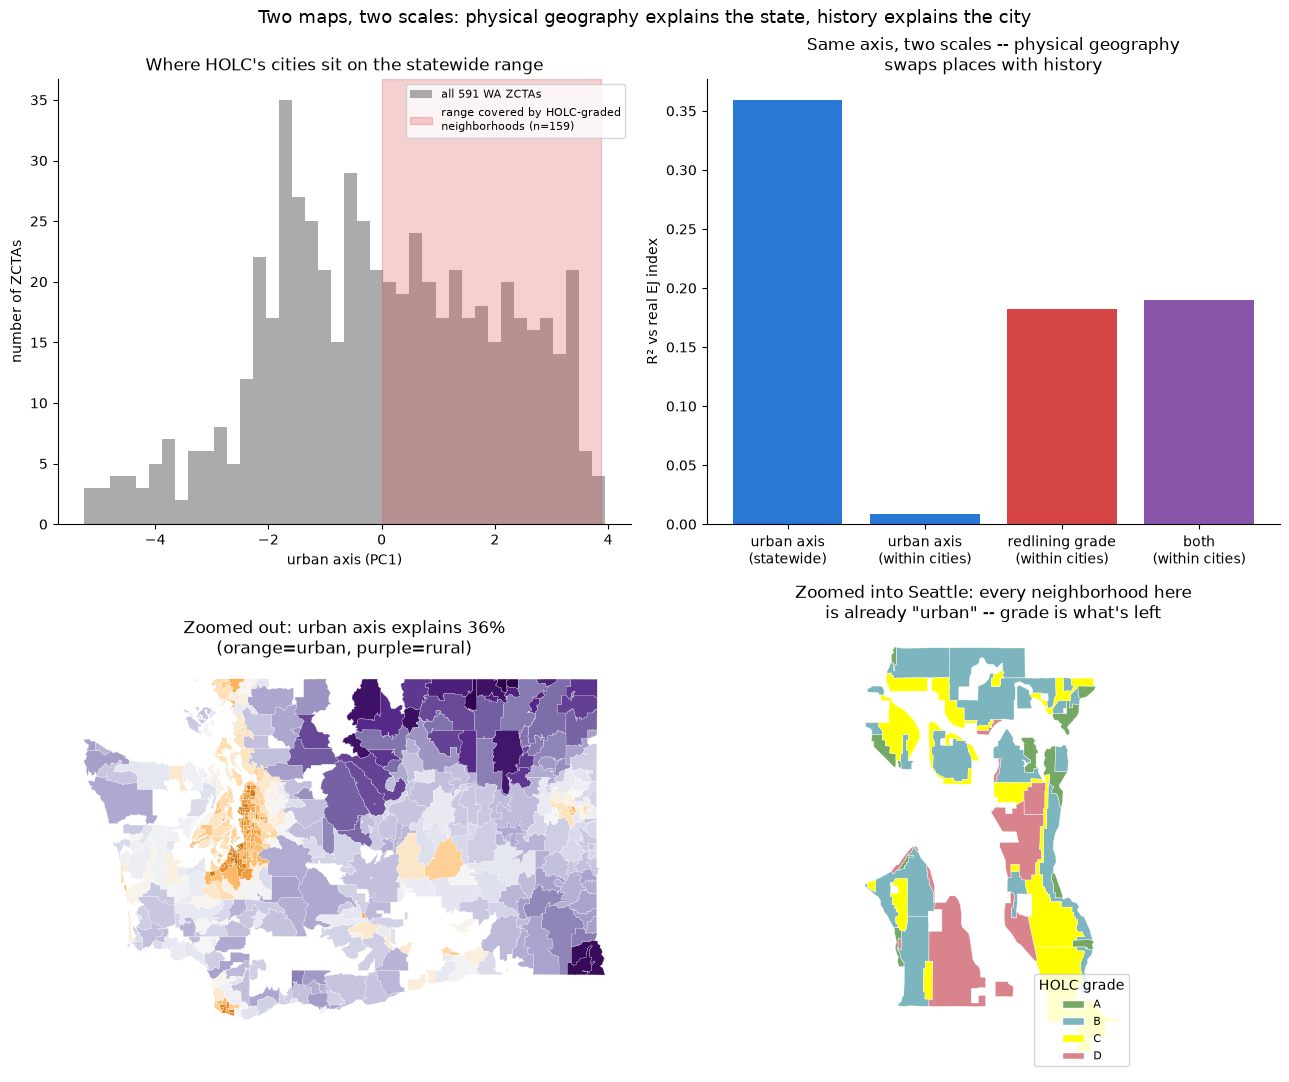

In [6]:
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

fig, axes = plt.subplots(2, 2, figsize=(13, 11))

# 1. distribution: statewide urban_axis, with the HOLC-covered range shaded
ax = axes[0, 0]
ax.hist(zctas["urban_axis"], bins=40, color="#888888", alpha=0.7, label="all 591 WA ZCTAs")
ax.axvspan(holc_valid["urban_axis"].min(), holc_valid["urban_axis"].max(), color="#d64545", alpha=0.25,
           label="range covered by HOLC-graded\nneighborhoods (n=159)")
ax.set_xlabel("urban axis (PC1)")
ax.set_ylabel("number of ZCTAs")
ax.set_title("Where HOLC's cities sit on the statewide range")
ax.legend(fontsize=8)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# 2. R^2 comparison at the two scales
ax = axes[0, 1]
labels = ["urban axis\n(statewide)", "urban axis\n(within cities)", "redlining grade\n(within cities)", "both\n(within cities)"]
vals = [r2_state_urban, r2_city_urban, r2_city_grade, r2_city_both]
colors = ["#2a78d6", "#2a78d6", "#d64545", "#8855aa"]
ax.bar(labels, vals, color=colors)
ax.set_ylabel("R² vs real EJ index")
ax.set_title("Same axis, two scales -- physical geography\nswaps places with history")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)


def rings(geometry):
    coords = geometry["coordinates"]
    polys = [coords] if geometry["type"] == "Polygon" else coords
    for poly in polys:
        yield np.array(poly[0])


# 3. statewide map, colored by urban axis
ax = axes[1, 0]
feats_state = json.loads(zctas.to_json())["features"]
all_lats = np.concatenate([r[:, 1] for f in feats_state for r in rings(f["geometry"])])
lat_aspect = 1 / np.cos(np.radians(all_lats.mean()))
patches, values = [], []
for feat in feats_state:
    for ring in rings(feat["geometry"]):
        patches.append(Polygon(ring, closed=True))
        values.append(feat["properties"]["urban_axis"])
lim = max(abs(min(values)), abs(max(values)))
coll = PatchCollection(patches, cmap="PuOr_r")
coll.set_array(np.array(values))
coll.set_clim(-lim, lim)
coll.set_edgecolor("white")
coll.set_linewidth(0.15)
ax.add_collection(coll)
ax.autoscale_view()
ax.set_aspect(lat_aspect)
ax.axis("off")
ax.set_title(f"Zoomed out: urban axis explains {r2_state_urban:.0%}\n(orange=urban, purple=rural)")

# 4. Seattle only, colored by HOLC grade
ax = axes[1, 1]
seattle = holc_valid[holc_valid["city"] == "Seattle"]
feats_sea = json.loads(seattle.to_json())["features"]
sea_lats = np.concatenate([r[:, 1] for f in feats_sea for r in rings(f["geometry"])])
sea_aspect = 1 / np.cos(np.radians(sea_lats.mean()))
patches_sea, colors_sea = [], []
for feat in feats_sea:
    for ring in rings(feat["geometry"]):
        patches_sea.append(Polygon(ring, closed=True))
        colors_sea.append(GRADE_COLOR[feat["properties"]["grade"]])
coll2 = PatchCollection(patches_sea, facecolor=colors_sea, edgecolor="white", linewidth=0.3)
ax.add_collection(coll2)
ax.autoscale_view()
ax.set_aspect(sea_aspect)
ax.axis("off")
ax.set_title("Zoomed into Seattle: every neighborhood here\nis already \"urban\" -- grade is what's left")
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=GRADE_COLOR[g], edgecolor="white") for g in "ABCD"]
ax.legend(handles, ["A", "B", "C", "D"], loc="lower right", fontsize=8, title="HOLC grade")

fig.suptitle("Two maps, two scales: physical geography explains the state, history explains the city", fontsize=13)
fig.tight_layout()
fig.savefig("dc_ej_scale_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

## Source & caption notes

- **The question this answers:** `dc_ej_predictors.ipynb` found physical siting infrastructure explains 62% of WA's real EJ index, mostly via one urban/rural axis. `dc_ej_redlining.ipynb` found 1930s redlining grade explains 18% of the same index, but only within the 3 cities HOLC covered. Naive read: pick a winner, or add them together. Actual answer: neither -- they operate at different zoom levels.
- **Statewide (n=591 ZCTAs): urban axis alone, R²=0.359** (full 17-feature model: R²=0.616; leakage-corrected, see below). One fact -- is this place close to a city -- does a real, substantial chunk of the work.
- **Within the 3 HOLC-covered cities (n=159 neighborhoods): urban axis alone, R²=0.009** -- roughly 40x weaker, asserted in-notebook. Redlining grade alone: R²=0.182. Combined: barely more than grade alone -- the urban axis has almost nothing left to contribute at this zoom level.
- **Mechanism, checked not assumed:** urban-axis standard deviation is ~5x smaller within HOLC neighborhoods than statewide, and every single HOLC-graded neighborhood sits in roughly the top third of the full statewide range. HOLC only ever graded places that were already about as urban as Washington gets. The variable that explains most of the state has almost no room left to vary once you're only comparing neighborhoods within a city.
- **Leakage correction (2026-08-28):** `urban_axis` was first built via PCA on all 21 physical indicators, including the 4 hazard columns that are literally the raw ingredients of `env_burden` -- half of `ej_index`'s own formula. Rebuilt excluding them entirely from the PCA input: statewide R² for the axis alone drops from 0.435 to 0.359. The qualitative finding (dominant statewide, quiet within cities, redlining fills the gap) survives -- the drop-off ratio is if anything slightly more dramatic with the honest number, not less. Full story in `dc_ej_urban_axis_pca.ipynb`'s intro.
- **Not a contradiction between the two companion pieces -- a resolution.** Same underlying quantity (real EJ index), same data, two honest answers depending entirely on how far you zoom out.
- **Not published as its own post** -- its actual payoff (why redlining explains so much within cities specifically) was folded into the closing section of `dc_ej_redlining.ipynb` and its caption instead. Kept here as the full worked mechanism and visualization those reference.
- Images: dc_ej_scale_dependence.png (distribution + R² comparison + statewide map + Seattle zoom, 4 panels).